In [ ]:
import pandas as pd
import random
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
import numpy as np


random.seed(42)

train_set=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/졸업논문/train_set.csv")

train_set.set_index(train_set.columns[0],inplace=True)


In [ ]:
train_set.value_counts('state')

,count
state,
0,175
1,121


In [ ]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

X_train=train_set.drop(columns=['state'])
y_train=train_set['state']



In [ ]:

from sklearn.metrics import classification_report, confusion_matrix,roc_auc_score, roc_curve
pipeline_cv=Pipeline([
    ('scaler',StandardScaler()),
     ('model',SVC(kernel='rbf',class_weight='balanced',probability=True,random_state=42))])
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

scoring={'roc_auc':'roc_auc', 'accuracy':'accuracy', 'recall':'recall'}
cv_results=cross_validate(pipeline_cv,X_train,y_train,cv=cv,scoring=scoring)

print("=== 5-Fold Cross-Validation Results (Training Set) ===")
print(f"Mean CV ROC-AUC:  {np.mean(cv_results['test_roc_auc']):.3f} (+/- {np.std(cv_results['test_roc_auc']):.3f})")
print(f"Mean CV Accuracy: {np.mean(cv_results['test_accuracy']):.3f}")
print(f"Mean CV Recall:   {np.mean(cv_results['test_recall']):.3f}\n")

=== 5-Fold Cross-Validation Results (Training Set) ===
Mean CV ROC-AUC:  0.965 (+/- 0.016)
Mean CV Accuracy: 0.919
Mean CV Recall:   0.843



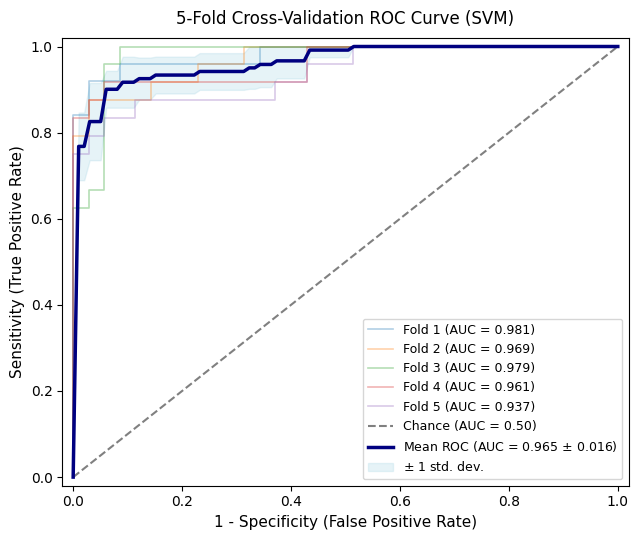

In [ ]:
# --- Figure 4A: ROC Curve 시각화 코드 (기존 코드 아래에 붙여넣기) ---
tprs = []
aucs = []
mean_fpr = np.linspace(0, 1, 100)

plt.figure(figsize=(6.5, 5.5))

# 5-Fold 각각의 ROC Curve 계산 및 그리기
for fold, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train)):
    X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train.iloc[val_idx], y_train.iloc[val_idx]

    pipeline_cv.fit(X_tr, y_tr)
    y_proba = pipeline_cv.predict_proba(X_va)[:, 1]

    fpr, tpr, _ = roc_curve(y_va, y_proba)
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs.append(interp_tpr)

    roc_auc = roc_auc_score(y_va, y_proba)
    aucs.append(roc_auc)
    plt.plot(
        fpr,
        tpr,
        lw=1.2,
        alpha=0.35,
        label=f"Fold {fold+1} (AUC = {roc_auc:.3f})",
    )

# Reference Line (Chance)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    lw=1.5,
    color="gray",
    label="Chance (AUC = 0.50)",
)

# Mean ROC Curve
mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = np.mean(aucs)
std_auc = np.std(aucs)

plt.plot(
    mean_fpr,
    mean_tpr,
    color="navy",
    lw=2.5,
    label=f"Mean ROC (AUC = {mean_auc:.3f} $\\pm$ {std_auc:.3f})",
)

# Standard Deviation Area
std_tpr = np.std(tprs, axis=0)
tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
plt.fill_between(
    mean_fpr,
    tprs_lower,
    tprs_upper,
    color="lightblue",
    alpha=0.3,
    label=r"$\pm$ 1 std. dev.",
)

# 축 라벨 및 레이아웃 설정
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.xlabel("1 - Specificity (False Positive Rate)", fontsize=11)
plt.ylabel("Sensitivity (True Positive Rate)", fontsize=11)
plt.title("5-Fold Cross-Validation ROC Curve (SVM)", fontsize=12, pad=10)
plt.legend(loc="lower right", fontsize=9)
plt.tight_layout()

In [ ]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)

model=SVC(kernel='rbf',class_weight='balanced',probability=True,random_state=42) # rbf로 비선형 kernel trick 으로 문제 해결
model.fit(X_train_scaled,y_train)

SVC(class_weight='balanced', probability=True, random_state=42)

In [ ]:
test_set=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/졸업논문/test_set.csv")
test_set.set_index(test_set.columns[0],inplace=True)

In [ ]:
test_set.value_counts('state')

,count
state,
0,42
1,23


In [ ]:
X_test=test_set.drop(columns=['state'])
y_test=test_set['state']

X_test_scaled=scaler.transform(X_test)

y_pred=model.predict(X_test_scaled)

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix,roc_auc_score, roc_curve



print(confusion_matrix(y_test,y_pred))


[[40  2]
 [ 3 20]]


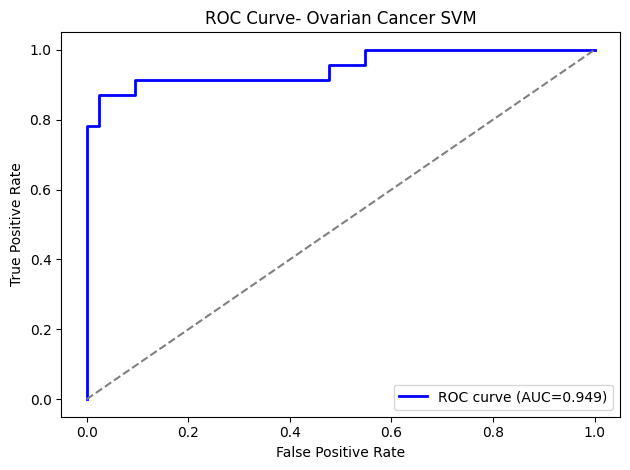

In [ ]:
y_prob=model.predict_proba(X_test_scaled)[:,1]
fpr,tpr,thresholds=roc_curve(y_test,y_prob)
auc=roc_auc_score(y_test,y_prob)

import matplotlib.pyplot as plt

plt.plot(fpr,tpr,color='blue',lw=2,label=f'ROC curve (AUC={auc:.3f})')
plt.plot([0,1],[0,1],color='gray',linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel("True Positive Rate")
plt.title("ROC Curve- Ovarian Cancer SVM")
plt.legend(loc='lower right')
plt.tight_layout()
# log TPM 을하고 scaler( 선행 연구에서 어떻게 전처리 하는지, 생물학적 해석(GO, GSEA), FDR 낮은거 상위 10개로 boxplot  개별마커, 조직에서도 잘 분류되는 유전자,  )
# 전체에서 히트맵(정상,난소암, 학습, test label 도 해서 히트맵 그리기), 학습 test(으로도 boxplot, )



#



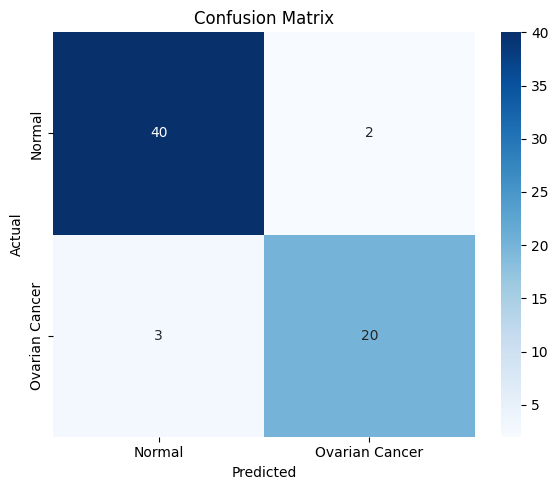

In [ ]:
import seaborn as sns
cm=confusion_matrix(y_test,y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm,
            annot=True,          # 숫자 표시
            fmt='d',             # 정수형
            cmap='Blues',        # 색상
            xticklabels=['Normal', 'Ovarian Cancer'],
            yticklabels=['Normal', 'Ovarian Cancer'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

In [ ]:
TN, FP, FN, TP = cm.ravel()

sensitivity = TP / (TP + FN)
specificity = TN / (TN + FP)
accuracy=(TP+TN)/(TP+TN+FP+FN)

print(f"Sensitivity: {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"Accuracy: {accuracy:.4f}")

Sensitivity: 0.8696
Specificity: 0.9524
Accuracy: 0.9231


In [ ]:
import pandas as pd

log2=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/졸업논문/log2.csv")
log2

,Unnamed: 0,ENSG00000103316,ENSG00000161835,ENSG00000158578,ENSG00000184205,ENSG00000118503,ENSG00000185909,ENSG00000157654,ENSG00000151575,ENSG00000179094,...,ENSG00000198242,ENSG00000179144,ENSG00000171858,ENSG00000177954,ENSG00000169442,ENSG00000083845,ENSG00000112306,ENSG00000109475,ENSG00000071082,ENSG00000172809
0,GSM5563788,5.084297,0.396807,0.396807,6.218183,1.180380,6.733691,7.174084,6.260501,0.707686,...,5.375862,4.835086,4.851000,7.988436,6.278264,7.148558,6.759214,6.335943,6.707708,5.137169
1,GSM5563789,3.402917,2.862921,5.088549,5.601604,5.659308,3.572702,5.893734,4.777182,5.129958,...,8.900534,8.990398,8.689402,11.209018,10.764704,10.662879,10.050926,10.097332,10.033756,9.029216
2,GSM5563790,2.393302,3.540270,3.950672,5.147878,5.552706,5.415661,5.326716,4.943691,4.818796,...,8.642271,8.992381,8.615923,10.900327,10.194248,10.360306,9.933762,9.876158,9.769109,8.815716
3,GSM5563791,4.087491,3.816721,3.713857,6.259987,7.435668,3.713857,6.043761,4.864027,6.455979,...,10.282662,10.353344,9.966907,12.038294,11.704680,11.611851,11.526692,11.388455,11.194358,10.188694
4,GSM5563792,4.381732,1.546278,2.887933,5.044851,6.542105,4.897696,4.548888,5.300583,5.178376,...,10.149049,9.765541,9.968158,12.354599,11.440614,12.250592,11.381257,11.426253,11.051653,9.948663
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
356,GSM5565747,6.496482,3.573563,7.806596,6.680296,4.921659,7.780000,6.234465,6.560391,2.528866,...,6.053835,4.749571,5.946313,8.337156,5.187572,6.194743,6.989769,6.950556,7.094213,6.260351
357,GSM5566073,5.875509,1.267557,5.854605,6.482094,3.914120,6.509099,6.720267,5.072742,1.427093,...,5.956221,6.185556,5.618759,8.481348,7.562599,6.163062,7.246863,7.457922,6.561637,5.854605
358,GSM5566081,4.904410,0.000000,4.861521,4.212922,2.646936,6.778420,6.766845,6.719593,5.025921,...,6.707535,7.484436,6.398085,9.071094,8.233674,6.921008,8.283265,8.101685,8.323327,6.743413
359,GSM5566086,5.340565,5.340565,5.474828,0.000000,5.027510,0.000000,9.492385,5.710836,6.322652,...,6.802920,5.474828,6.005223,8.272660,6.901594,6.091364,8.344583,7.919295,7.744217,5.815783


In [ ]:
import seaborn as sns
log2.set_index(log2.columns[0],inplace=True)

In [ ]:
meta_data=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/졸업논문/metadata.csv")
meta_data.set_index(meta_data.columns[0],inplace=True)

In [ ]:
df_merged =meta_data.join(log2, how="inner")
df_merged

,Sample,Patient,Group,Group_raw,Sex,Age,Stage,Institute,DataSplit,Project,...,ENSG00000198242,ENSG00000179144,ENSG00000171858,ENSG00000177954,ENSG00000169442,ENSG00000083845,ENSG00000112306,ENSG00000109475,ENSG00000071082,ENSG00000172809
Unnamed: 0,,,,,,,,,,,,,,,,,,,,,
GSM5563788,GSM5563788,Vumc-HD-101-TR922,AC,Asymptomatic controls,F,35,AC,VUMC,Training,PRJNA761450,...,5.375862,4.835086,4.851000,7.988436,6.278264,7.148558,6.759214,6.335943,6.707708,5.137169
GSM5563789,GSM5563789,Vumc-HD-103-TR923,AC,Asymptomatic controls,F,54,AC,VUMC,Evaluation,PRJNA761450,...,8.900534,8.990398,8.689402,11.209018,10.764704,10.662879,10.050926,10.097332,10.033756,9.029216
GSM5563790,GSM5563790,Vumc-HD-108-TR924,AC,Asymptomatic controls,F,56,AC,VUMC,Validation,PRJNA761450,...,8.642271,8.992381,8.615923,10.900327,10.194248,10.360306,9.933762,9.876158,9.769109,8.815716
GSM5563791,GSM5563791,Vumc-HD-127-TR925,AC,Asymptomatic controls,F,52,AC,VUMC,Training,PRJNA761450,...,10.282662,10.353344,9.966907,12.038294,11.704680,11.611851,11.526692,11.388455,11.194358,10.188694
GSM5563792,GSM5563792,Vumc-HD-130-TR926,AC,Asymptomatic controls,F,57,AC,VUMC,Evaluation,PRJNA761450,...,10.149049,9.765541,9.968158,12.354599,11.440614,12.250592,11.381257,11.426253,11.051653,9.948663
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GSM5565747,GSM5565747,MGH-OVARY-43-TR1263,OVCAR,Ovarian cancer,F,55,II,MGH,Validation,PRJNA761450,...,6.053835,4.749571,5.946313,8.337156,5.187572,6.194743,6.989769,6.950556,7.094213,6.260351
GSM5566073,GSM5566073,UMCU-HC-1-0197-TR824,AC,Asymptomatic controls,F,54,AC,UMCU,Validation,PRJNA761450,...,5.956221,6.185556,5.618759,8.481348,7.562599,6.163062,7.246863,7.457922,6.561637,5.854605
GSM5566081,GSM5566081,UMCU-HC-1-0205-TR811,AC,Asymptomatic controls,F,40,AC,UMCU,Validation,PRJNA761450,...,6.707535,7.484436,6.398085,9.071094,8.233674,6.921008,8.283265,8.101685,8.323327,6.743413


In [ ]:
print(df_merged.columns)

Index(['Sample', 'Patient', 'Group', 'Group_raw', 'Sex', 'Age', 'Stage',
       'Institute', 'DataSplit', 'Project', 'Age_group', 'strata', 'split',
       'ENSG00000103316', 'ENSG00000161835', 'ENSG00000158578',
       'ENSG00000184205', 'ENSG00000118503', 'ENSG00000185909',
       'ENSG00000157654', 'ENSG00000151575', 'ENSG00000179094',
       'ENSG00000141682', 'ENSG00000198242', 'ENSG00000179144',
       'ENSG00000171858', 'ENSG00000177954', 'ENSG00000169442',
       'ENSG00000083845', 'ENSG00000112306', 'ENSG00000109475',
       'ENSG00000071082', 'ENSG00000172809'],
      dtype='object')


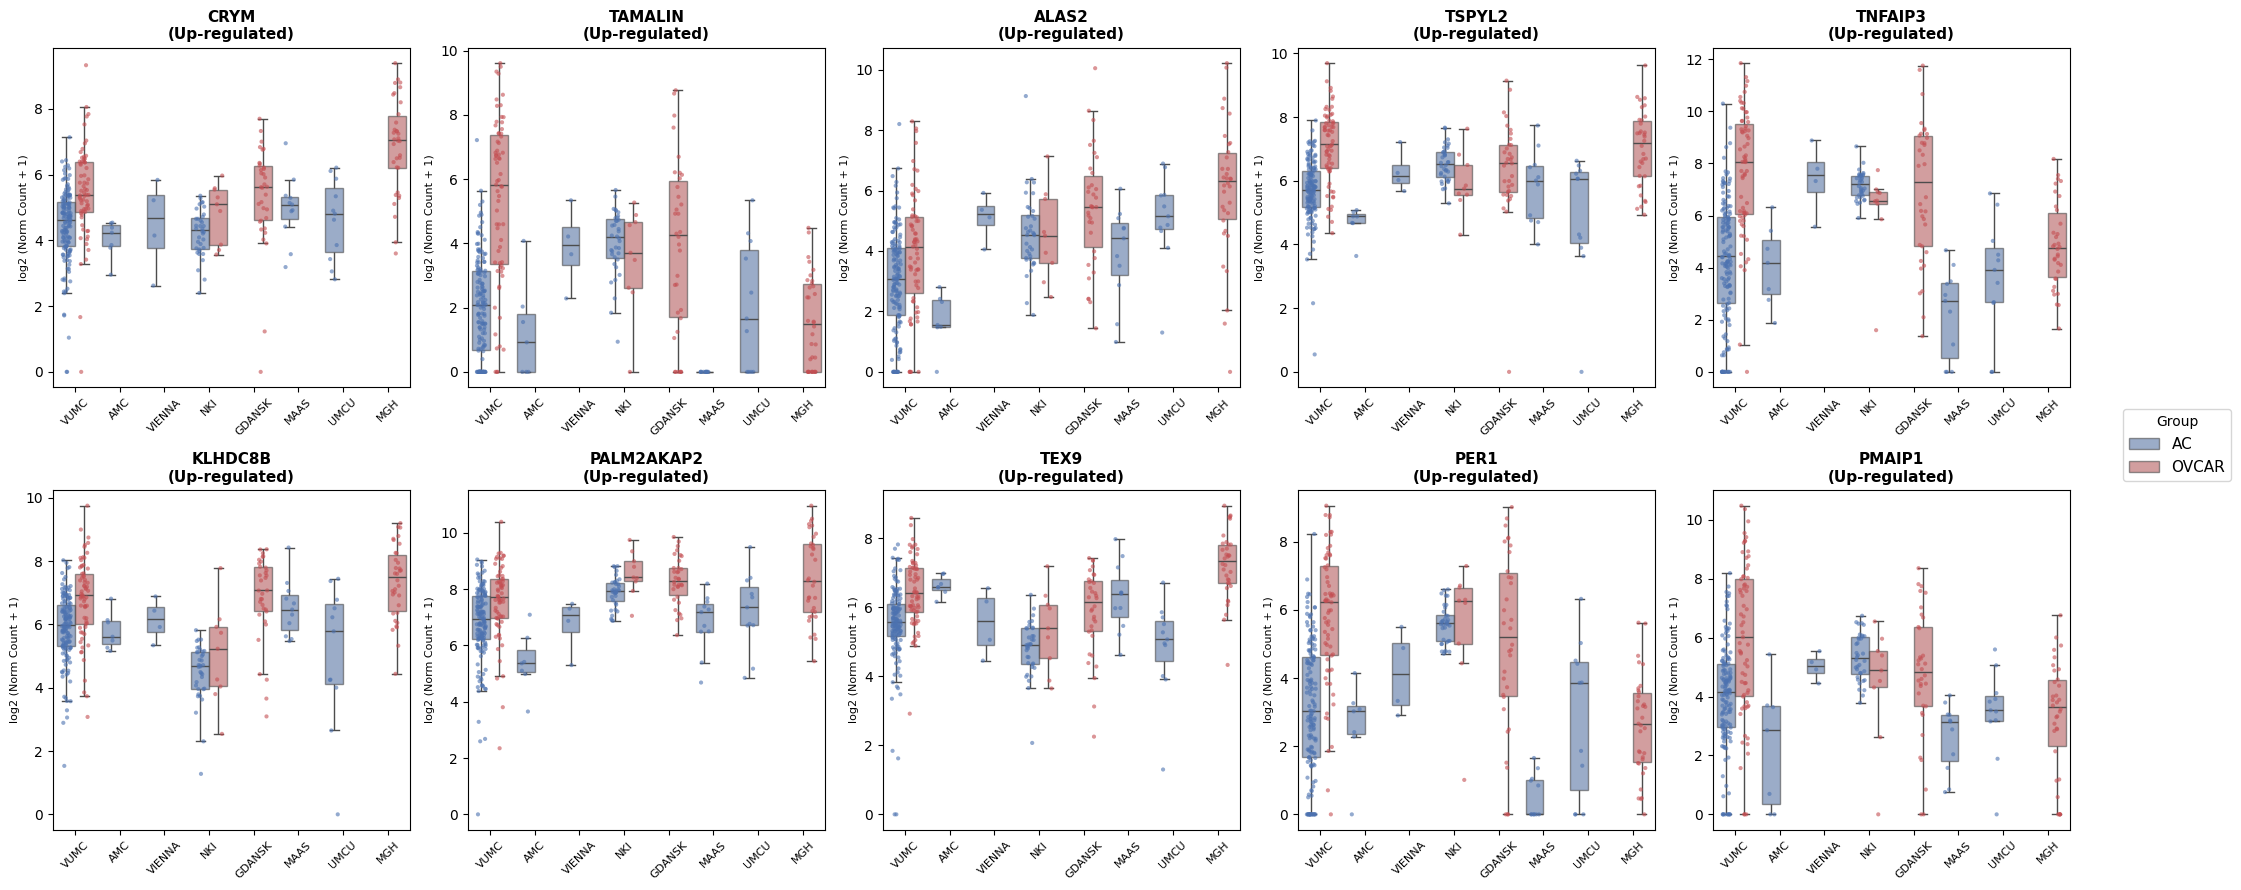

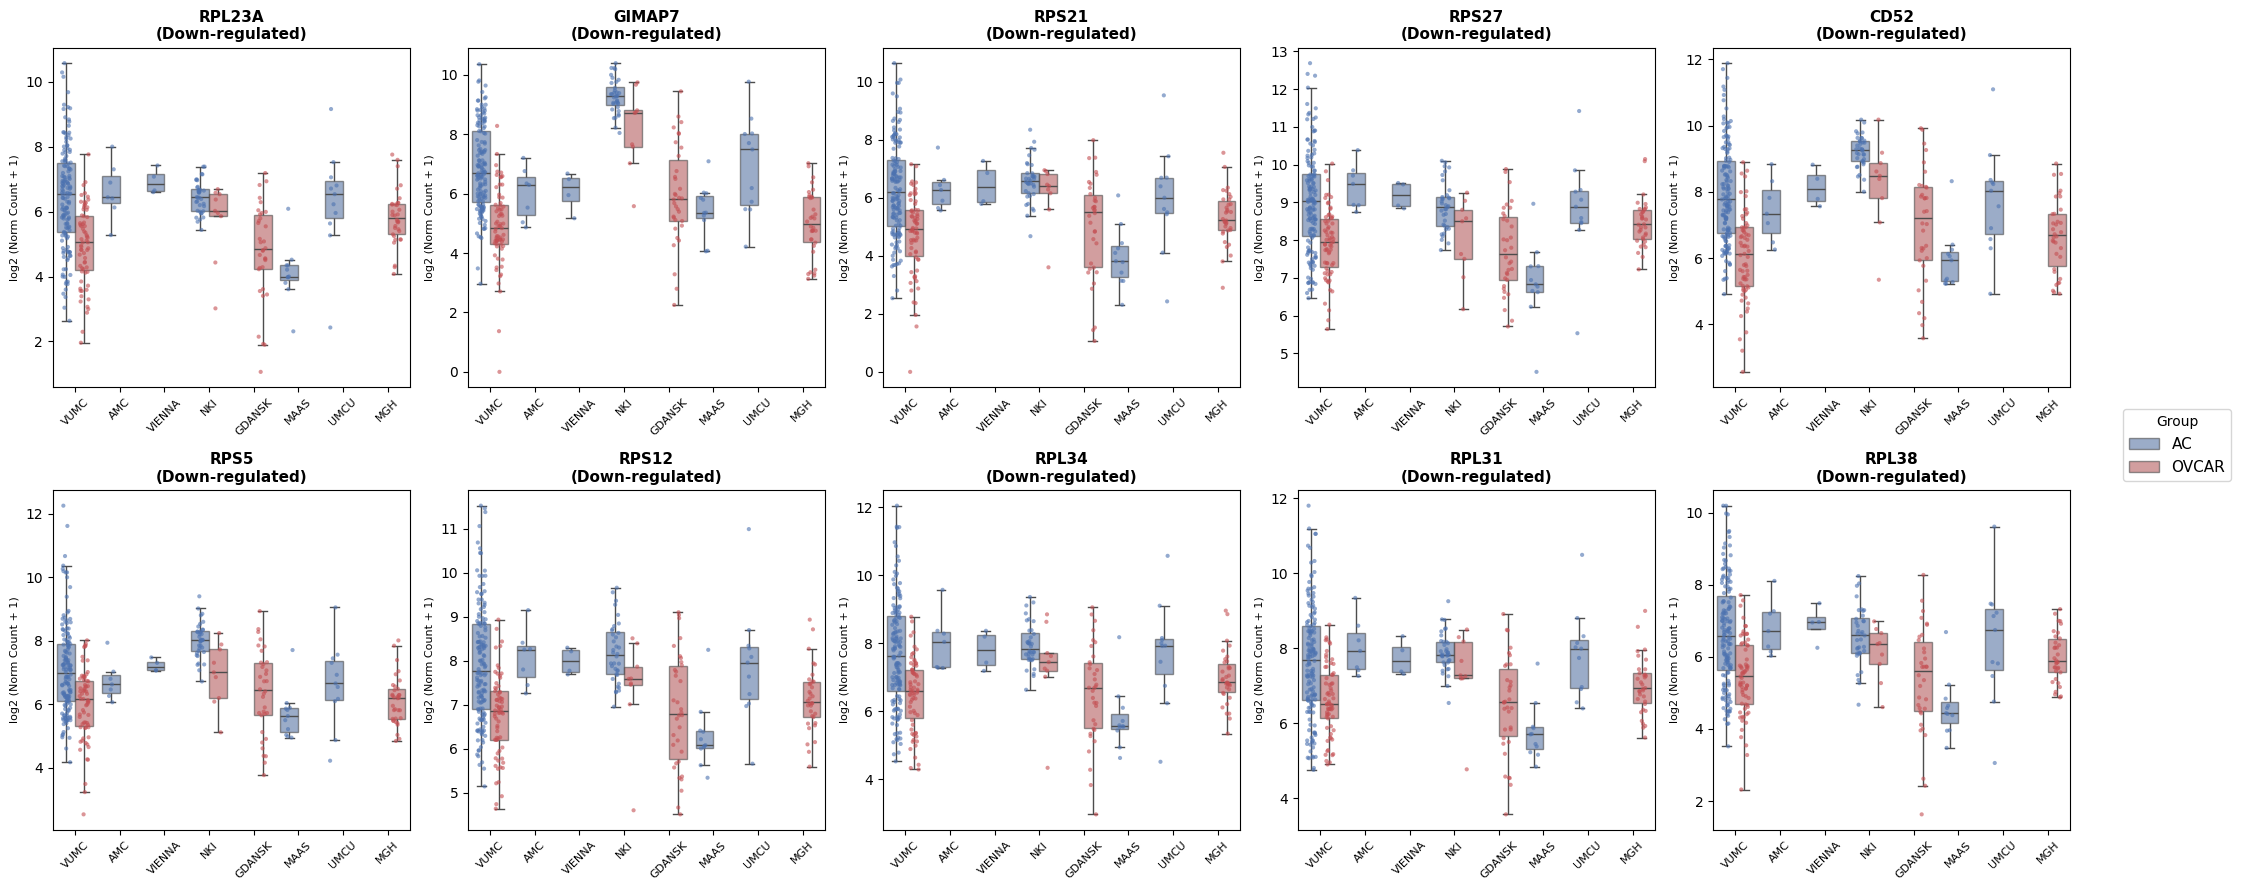

In [ ]:
up_genes = [
    "ENSG00000103316",
    "ENSG00000161835",
    "ENSG00000158578",
    "ENSG00000184205",
    "ENSG00000118503",
    "ENSG00000185909",
    "ENSG00000157654",
    "ENSG00000151575",
    "ENSG00000179094",
    "ENSG00000141682",
]

down_genes = [
    "ENSG00000198242",
    "ENSG00000179144",
    "ENSG00000171858",
    "ENSG00000177954",
    "ENSG00000169442",
    "ENSG00000083845",
    "ENSG00000112306",
    "ENSG00000109475",
    "ENSG00000071082",
    "ENSG00000172809",
]

gene_map = {
    # Up-regulated Genes
    "ENSG00000103316": "CRYM",
    "ENSG00000161835": "TAMALIN",
    "ENSG00000158578": "ALAS2",
    "ENSG00000184205": "TSPYL2",
    "ENSG00000118503": "TNFAIP3",
    "ENSG00000185909": "KLHDC8B",
    "ENSG00000157654": "PALM2AKAP2",
    "ENSG00000151575": "TEX9",
    "ENSG00000179094": "PER1",
    "ENSG00000141682": "PMAIP1",  # CA125
    # Down-regulated Genes
    "ENSG00000198242": "RPL23A",
    "ENSG00000179144": "GIMAP7",
    "ENSG00000171858": "RPS21",
    "ENSG00000177954": "RPS27",
    "ENSG00000169442": "CD52",
    "ENSG00000083845": "RPS5",
    "ENSG00000112306": "RPS12",
    "ENSG00000109475": "RPL34",
    "ENSG00000071082": "RPL31",
    "ENSG00000172809": "RPL38",
}

batch_col = "Institute"  # 수집 기관/배치 열 이름
state_col = "Group"  # 질병 상태 열 이름 (Normal vs OVCAR)

palette_dict={"AC": "#4C72B0", "OVCAR": "#C44E52"}

def plot_stratified_degs_symbol(data, gene_list, title_prefix, filename):
    fig, axes = plt.subplots(2, 5, figsize=(22, 9))
    axes = axes.flatten()

    for idx, gene in enumerate(gene_list):
        ax = axes[idx]

        # Gene Symbol 변환
        symbol = gene_map.get(gene, gene)

        # Boxplot
        sns.boxplot(
            data=data,
            x=batch_col,
            y=gene,
            hue=state_col,
            palette=palette_dict,
            ax=ax,
            fliersize=0,
            boxprops=dict(alpha=0.6),
        )

        # Stripplot
        sns.stripplot(
            data=data,
            x=batch_col,
            y=gene,
            hue=state_col,
            palette=palette_dict,
            dodge=True,
            jitter=0.2,
            alpha=0.6,
            size=3,
            ax=ax,
        )

        # 개별 서브플롯 범례 제거
        if ax.get_legend():
            ax.get_legend().remove()

        # [수정] 제목 양식: Gene Symbol \n (Up-regulated) 또는 (Down-regulated)
        ax.set_title(
            f"{symbol}\n({title_prefix})", fontsize=11, fontweight="bold"
        )
        ax.set_xlabel("", fontsize=8)
        ax.set_ylabel("log2 (Norm Count + 1)", fontsize=8)
        ax.tick_params(axis="x", rotation=45, labelsize=8)

    # 통합 범례 우측 지정
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles[:2],
        labels[:2],
        title="Group",
        loc="center right",
        bbox_to_anchor=(1.02, 0.5),
        fontsize=11,
    )

    plt.tight_layout(rect=[0, 0, 0.95, 1])
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()


# ==========================================
# 3. 실행 구문
# ==========================================
plot_stratified_degs_symbol(
    df_merged, up_genes, "Up-regulated", "Figure5A_Top10_Up_DEGs.png"
)
plot_stratified_degs_symbol(
    df_merged, down_genes, "Down-regulated", "Figure5B_Top10_Down_DEGs.png"
)



In [ ]:
sig_genes=["ENSG00000103316",
    "ENSG00000161835",
    "ENSG00000158578",
    "ENSG00000184205",
    "ENSG00000118503",
    "ENSG00000198242",
    "ENSG00000179144",
    "ENSG00000171858",
    "ENSG00000177954",
    "ENSG00000169442"
           ]


up_genes = {

    "ENSG00000103316": "CRYM",
    "ENSG00000161835": "TAMALIN",
    "ENSG00000158578": "ALAS2",
    "ENSG00000184205": "TSPYL2",
    "ENSG00000118503": "TNFAIP3",
    }
down_genes={"ENSG00000198242": "RPL23A",
    "ENSG00000179144": "GIMAP7",
    "ENSG00000171858": "RPS21",
    "ENSG00000177954": "RPS27",
    "ENSG00000169442": "CD52"}

In [ ]:
up=log2.iloc[:,0:5]
down=log2.iloc[:,10:15]
down

,ENSG00000198242,ENSG00000179144,ENSG00000171858,ENSG00000177954,ENSG00000169442
Unnamed: 0,,,,,
GSM5563788,5.375862,4.835086,4.851000,7.988436,6.278264
GSM5563789,8.900534,8.990398,8.689402,11.209018,10.764704
GSM5563790,8.642271,8.992381,8.615923,10.900327,10.194248
GSM5563791,10.282662,10.353344,9.966907,12.038294,11.704680
GSM5563792,10.149049,9.765541,9.968158,12.354599,11.440614
...,...,...,...,...,...
GSM5565747,6.053835,4.749571,5.946313,8.337156,5.187572
GSM5566073,5.956221,6.185556,5.618759,8.481348,7.562599
GSM5566081,6.707535,7.484436,6.398085,9.071094,8.233674


In [ ]:
down

,ENSG00000198242,ENSG00000179144,ENSG00000171858,ENSG00000177954,ENSG00000169442
Unnamed: 0,,,,,
GSM5563788,5.375862,4.835086,4.851000,7.988436,6.278264
GSM5563789,8.900534,8.990398,8.689402,11.209018,10.764704
GSM5563790,8.642271,8.992381,8.615923,10.900327,10.194248
GSM5563791,10.282662,10.353344,9.966907,12.038294,11.704680
GSM5563792,10.149049,9.765541,9.968158,12.354599,11.440614
...,...,...,...,...,...
GSM5565747,6.053835,4.749571,5.946313,8.337156,5.187572
GSM5566073,5.956221,6.185556,5.618759,8.481348,7.562599
GSM5566081,6.707535,7.484436,6.398085,9.071094,8.233674


In [ ]:
!pip install statannotations
from statannotations.Annotator import Annotator
import matplotlib.pyplot as plt
import seaborn as sns

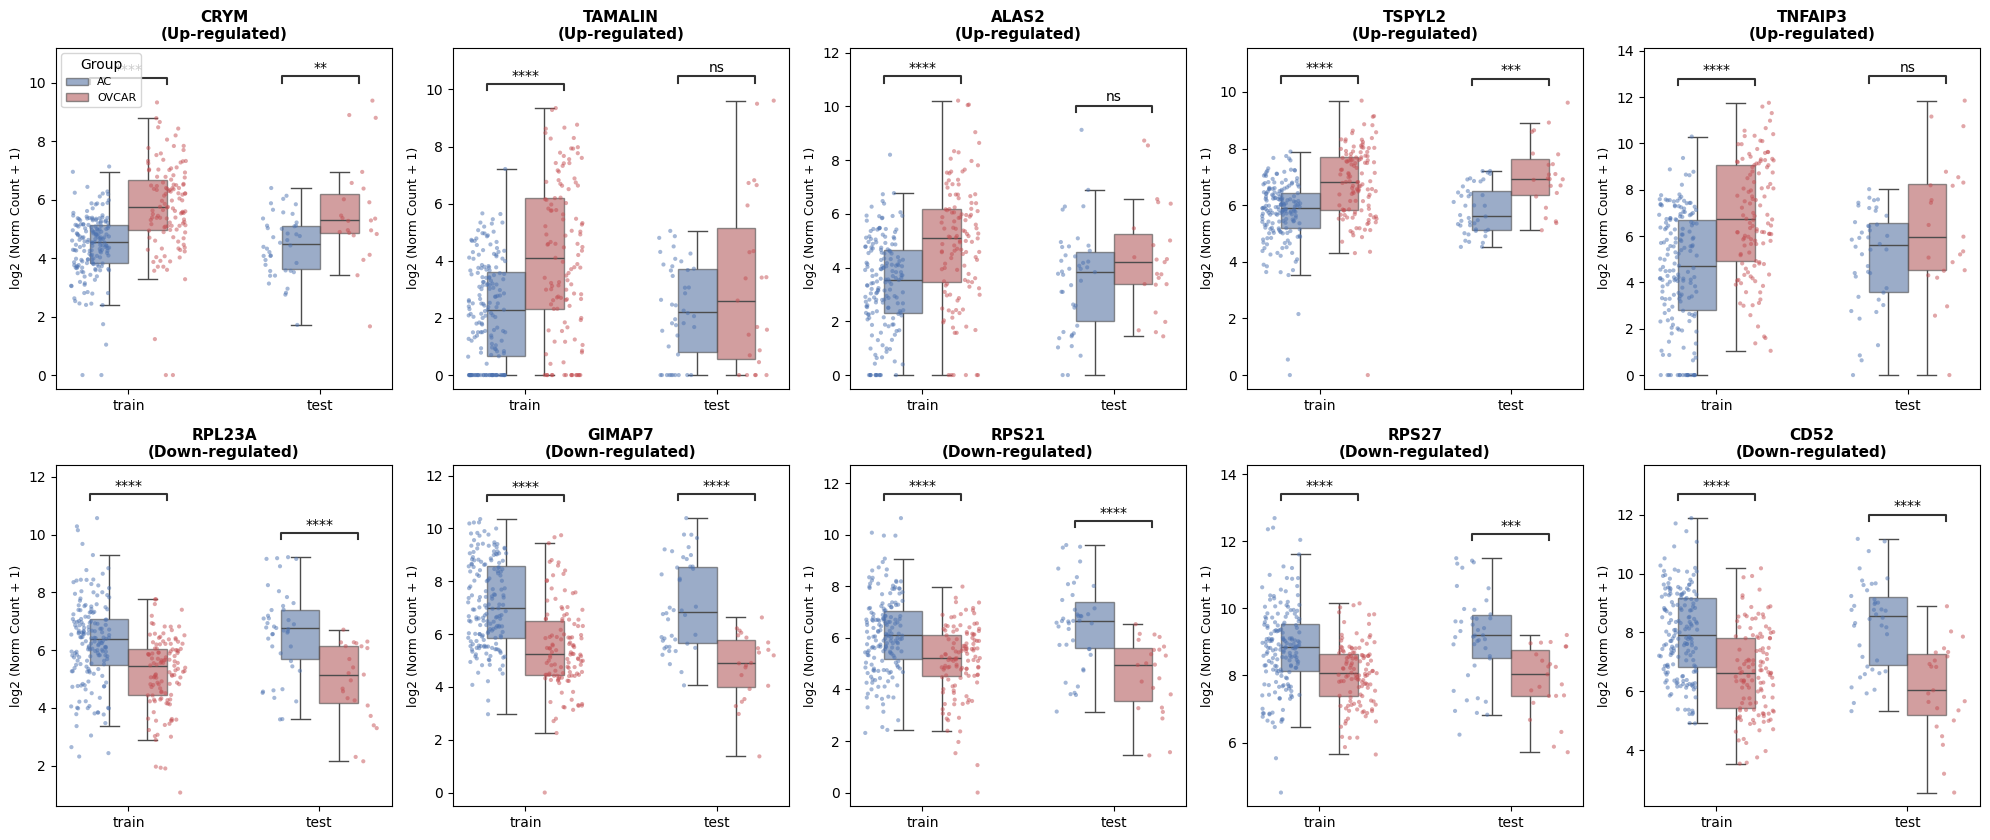

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from statannotations.Annotator import Annotator

# 데이터 결합
up_merged = meta_data.join(up, how="inner")
down_merged = meta_data.join(down, how="inner")

# Group(AC / OVCAR) 색상 팔레트 사용
group_palette = {"AC": "#4C72B0", "OVCAR": "#C44E52"}

# ==========================================
fig, axes = plt.subplots(2, 5, figsize=(20, 8.5))
axes = axes.flatten()

# 통계 검정 대상: Train 내 AC vs OVCAR, Test 내 AC vs OVCAR
pairs = [
    (("train", "AC"), ("train", "OVCAR")),
    (("test", "AC"), ("test", "OVCAR")),
]

# ------------------------------------------
# (1) Up-regulated 유전자 (상단 5개)
# ------------------------------------------
for idx, gene in enumerate(up_genes):
    ax = axes[idx]
    symbol = up_genes.get(gene, gene)

    # Boxplot (x축=split, hue=Group)
    sns.boxplot(
        data=up_merged,
        x="split",
        y=gene,
        hue="Group",
        order=["train", "test"],
        hue_order=["AC", "OVCAR"],
        palette=group_palette,
        ax=ax,
        width=0.4,
        fliersize=0,
        boxprops=dict(alpha=0.6),
    )

    # Stripplot
    sns.stripplot(
        data=up_merged,
        x="split",
        y=gene,
        hue="Group",
        order=["train", "test"],
        hue_order=["AC", "OVCAR"],
        palette=group_palette,
        dodge=True,
        jitter=0.2,
        alpha=0.5,
        size=3,
        ax=ax,
        legend=False,  # 점 범주 중복 제거
    )

    # 통계 검정 및 별표 표기
    annotator = Annotator(
        ax,
        pairs=pairs,
        data=up_merged,
        x="split",
        y=gene,
        hue="Group",
        order=["train", "test"],
        hue_order=["AC", "OVCAR"],
    )
    annotator.configure(
        test="Mann-Whitney", text_format="star", loc="inside", verbose=False
    )
    annotator.apply_and_annotate()

    ax.set_title(f"{symbol}\n(Up-regulated)", fontsize=11, fontweight="bold")
    ax.set_xlabel("", fontsize=9)
    ax.set_ylabel("log2 (Norm Count + 1)", fontsize=9)

    # 첫 번째 서브플롯(CRYM)에만 범주 남기기
    if idx == 0:
        ax.legend(title="Group", loc="upper left", fontsize=8)
    else:
        ax.get_legend().remove()


# ------------------------------------------
# (2) Down-regulated 유전자 (하단 5개)
# ------------------------------------------
for idx, gene in enumerate(down_genes):
    ax = axes[idx + 5]
    symbol = down_genes.get(gene, gene)

    # Boxplot
    sns.boxplot(
        data=down_merged,
        x="split",
        y=gene,
        hue="Group",
        order=["train", "test"],
        hue_order=["AC", "OVCAR"],
        palette=group_palette,
        ax=ax,
        width=0.4,
        fliersize=0,
        boxprops=dict(alpha=0.6),
    )

    # Stripplot
    sns.stripplot(
        data=down_merged,
        x="split",
        y=gene,
        hue="Group",
        order=["train", "test"],
        hue_order=["AC", "OVCAR"],
        palette=group_palette,
        dodge=True,
        jitter=0.2,
        alpha=0.5,
        size=3,
        ax=ax,
        legend=False,
    )

    # 통계 검정
    annotator = Annotator(
        ax,
        pairs=pairs,
        data=down_merged,
        x="split",
        y=gene,
        hue="Group",
        order=["train", "test"],
        hue_order=["AC", "OVCAR"],
    )
    annotator.configure(
        test="Mann-Whitney", text_format="star", loc="inside", verbose=False
    )
    annotator.apply_and_annotate()

    ax.set_title(f"{symbol}\n(Down-regulated)", fontsize=11, fontweight="bold")
    ax.set_xlabel("", fontsize=9)
    ax.set_ylabel("log2 (Norm Count + 1)", fontsize=9)
    ax.get_legend().remove()

plt.tight_layout()
plt.savefig("Figure3_Overall_DEGs_Split_Xaxis.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols

# 1. up_merged, down_merged에서 AC / OVCAR 분할
ac_up = up_merged[up_merged["Group"] == "AC"]
ovcar_up = up_merged[up_merged["Group"] == "OVCAR"]

ac_down = down_merged[down_merged["Group"] == "AC"]
ovcar_down = down_merged[down_merged["Group"] == "OVCAR"]

anova_results = []


# 2. Helper 함수: OLS + ANOVA 계산
def run_anova(df, ensembl_id):
    formula = f"`{ensembl_id}` ~ C(Institute)"
    model = ols(formula, data=df).fit()
    anova_table = sm.stats.anova_lm(model, typ=2)
    return anova_table.loc["C(Institute)", "PR(>F)"]


# 3. Up-regulated Genes 검정
for ensembl_id, symbol in up_genes.items():
    if ensembl_id in up_merged.columns:
        p_ac = run_anova(ac_up, ensembl_id)
        p_ovcar = run_anova(ovcar_up, ensembl_id)

        anova_results.append(
            {
                "Type": "Up",
                "Symbol": symbol,
                "Ensembl_ID": ensembl_id,
                "AC_ANOVA_p": round(p_ac, 4),
                "AC_Batch_Effect": "No (ns)" if p_ac > 0.05 else "Yes (*)",
                "OVCAR_ANOVA_p": round(p_ovcar, 4),
                "OVCAR_Batch_Effect": "No (ns)" if p_ovcar > 0.05 else "Yes (*)",
            }
        )

# 4. Down-regulated Genes 검정
for ensembl_id, symbol in down_genes.items():
    if ensembl_id in down_merged.columns:
        p_ac = run_anova(ac_down, ensembl_id)
        p_ovcar = run_anova(ovcar_down, ensembl_id)

        anova_results.append(
            {
                "Type": "Down",
                "Symbol": symbol,
                "Ensembl_ID": ensembl_id,
                "AC_ANOVA_p": round(p_ac, 4),
                "AC_Batch_Effect": "No (ns)" if p_ac > 0.05 else "Yes (*)",
                "OVCAR_ANOVA_p": round(p_ovcar, 4),
                "OVCAR_Batch_Effect": "No (ns)" if p_ovcar > 0.05 else "Yes (*)",
            }
        )

# 5. 결과 테이블 출력
results_df = pd.DataFrame(anova_results)
print("=== 기관(Institute) 간 ANOVA 검정 결과 ===")
print(results_df.to_string(index=False))

In [ ]:
up_genes = {

    "ENSG00000103316": "CRYM",
    "ENSG00000161835": "TAMALIN",
    "ENSG00000158578": "ALAS2",
    "ENSG00000184205": "TSPYL2",
    "ENSG00000118503": "TNFAIP3",
    }
down_genes={"ENSG00000198242": "RPL23A",
    "ENSG00000179144": "GIMAP7",
    "ENSG00000171858": "RPS21",
    "ENSG00000177954": "RPS27",
    "ENSG00000169442": "CD52"}

gene_map = {
    # Up-regulated Genes
    "ENSG00000103316": "CRYM",
    "ENSG00000161835": "TAMALIN",
    "ENSG00000158578": "ALAS2",
    "ENSG00000184205": "TSPYL2",
    "ENSG00000118503": "TNFAIP3",
    "ENSG00000185909": "KLHDC8B",
    "ENSG00000157654": "PALM2AKAP2",
    "ENSG00000151575": "TEX9",
    "ENSG00000179094": "PER1",
    "ENSG00000141682": "PMAIP1",  # CA125
    # Down-regulated Genes
    "ENSG00000198242": "RPL23A",
    "ENSG00000179144": "GIMAP7",
    "ENSG00000171858": "RPS21",
    "ENSG00000177954": "RPS27",
    "ENSG00000169442": "CD52",
    "ENSG00000083845": "RPS5",
    "ENSG00000112306": "RPS12",
    "ENSG00000109475": "RPL34",
    "ENSG00000071082": "RPL31",
    "ENSG00000172809": "RPL38",
}

In [ ]:
import pandas as pd
from scipy import stats

# 1. AC(정상군) 및 OVCAR(암군) 데이터 분할
ac_up = up_merged[up_merged["Group"] == "AC"]
ovcar_up = up_merged[up_merged["Group"] == "OVCAR"]

ac_down = down_merged[down_merged["Group"] == "AC"]
ovcar_down = down_merged[down_merged["Group"] == "OVCAR"]

anova_results = []


# 2. 기관(Institute) 간 SciPy One-way ANOVA 실행 함수
def get_institute_anova_p(df, ensembl_id):
    # 기관별로 데이터 그룹화
    grouped = [
        group[ensembl_id].dropna()
        for name, group in df.groupby("Institute")
        if len(group[ensembl_id].dropna()) > 0
    ]

    # 비교 가능한 기관이 2개 이상일 때만 ANOVA 수행
    if len(grouped) >= 2:
        f_stat, p_val = stats.f_oneway(*grouped)
        return p_val
    return None


# 3. Up-regulated 유전자 검정 (상단 5개)
for ensembl_id, symbol in up_genes.items():
    if ensembl_id in up_merged.columns:
        p_ac = get_institute_anova_p(ac_up, ensembl_id)
        p_ovcar = get_institute_anova_p(ovcar_up, ensembl_id)

        anova_results.append(
            {
                "Type": "Up",
                "Symbol": symbol,
                "Ensembl_ID": ensembl_id,
                "AC_ANOVA_p": round(p_ac, 4) if p_ac is not None else "N/A",
                "AC_Batch_Effect": (
                    "No (ns)"
                    if (p_ac is not None and p_ac > 0.05)
                    else "Yes (*)"
                ),
                "OVCAR_ANOVA_p": (
                    round(p_ovcar, 4) if p_ovcar is not None else "N/A"
                ),
                "OVCAR_Batch_Effect": (
                    "No (ns)"
                    if (p_ovcar is not None and p_ovcar > 0.05)
                    else "Yes (*)"
                ),
            }
        )

# 4. Down-regulated 유전자 검정 (하단 5개)
for ensembl_id, symbol in down_genes.items():
    if ensembl_id in down_merged.columns:
        p_ac = get_institute_anova_p(ac_down, ensembl_id)
        p_ovcar = get_institute_anova_p(ovcar_down, ensembl_id)

        anova_results.append(
            {
                "Type": "Down",
                "Symbol": symbol,
                "Ensembl_ID": ensembl_id,
                "AC_ANOVA_p": round(p_ac, 4) if p_ac is not None else "N/A",
                "AC_Batch_Effect": (
                    "No (ns)"
                    if (p_ac is not None and p_ac > 0.05)
                    else "Yes (*)"
                ),
                "OVCAR_ANOVA_p": (
                    round(p_ovcar, 4) if p_ovcar is not None else "N/A"
                ),
                "OVCAR_Batch_Effect": (
                    "No (ns)"
                    if (p_ovcar is not None and p_ovcar > 0.05)
                    else "Yes (*)"
                ),
            }
        )

# 5. 결과 데이터프레임 변환 및 출력
results_df = pd.DataFrame(anova_results)
print("=================== 기관(Institute) 간 ANOVA 검정 결과 ===================")
print(results_df.to_string(index=False))

=================== 기관(Institute) 간 ANOVA 검정 결과 ===================
Type  Symbol      Ensembl_ID  AC_ANOVA_p AC_Batch_Effect  OVCAR_ANOVA_p OVCAR_Batch_Effect
  Up    CRYM ENSG00000103316      0.3526         No (ns)         0.0000            Yes (*)
  Up TAMALIN ENSG00000161835      0.0000         Yes (*)         0.0000            Yes (*)
  Up   ALAS2 ENSG00000158578      0.0000         Yes (*)         0.0000            Yes (*)
  Up  TSPYL2 ENSG00000184205      0.0000         Yes (*)         0.0091            Yes (*)
  Up TNFAIP3 ENSG00000118503      0.0000         Yes (*)         0.0000            Yes (*)
Down  RPL23A ENSG00000198242      0.0000         Yes (*)         0.0008            Yes (*)
Down  GIMAP7 ENSG00000179144      0.0000         Yes (*)         0.0000            Yes (*)
Down   RPS21 ENSG00000171858      0.0000         Yes (*)         0.0150            Yes (*)
Down   RPS27 ENSG00000177954      0.0000         Yes (*)         0.0098            Yes (*)
Down    CD52 ENSG00000